In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import os
import sys
import glob
import uproot

def gaus(x, A, mean, std):
    return A * np.exp(-1 * (x - mean)**2 / 2*(std))

def sigmoid(x, A, mean, width):
    return (A / (1 + np.exp(-1 * width * (x - mean))))

proc_F_DJ_LGAD_50um_strip_10db_attenuation_LaserTuneScan_3_NEv1000_BV115000mV_Laser20.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_DJ_LGAD_50um_strip_10db_attenuation_LaserTuneScan_3_NEv1000_BV115000mV_Laser60.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_DJ_LGAD_50um_strip_10db_attenuation_LaserTuneScan_3_NEv1000_BV115000mV_Laser40.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_DJ_LGAD_50um_strip_10db_attenuation_LaserTuneScan_3_NEv1000_BV115000mV_Laser0.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_DJ_LGAD_50um_strip_10db_attenuation_LaserTuneScan_3_NEv1000_BV115000mV_Laser100.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_DJ_LGAD_50um_strip_10db_attenuation_LaserTuneScan_3_NEv1000_BV115000mV_Laser80.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root


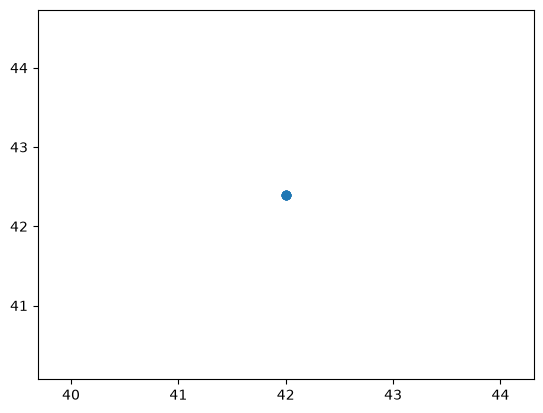

In [31]:
path = "../../Processed_data/"
# path = "../../ZAxisScan/"
# files = glob.glob(f"{path}proc_F_AC_LGAD_40um_strip_NEv*000_BV115000mV_Laser20pc_Temp16C_Zpos*_Xpos*00000.root")
files = glob.glob(f"{path}proc_F_DJ_LGAD_50um_strip_10db_attenuation_LaserTuneScan_3_NEv1000_BV115000mV_Laser*pc_Temp16C_Zpos*_Xpos*_Ypos*00000.root")

# files = glob.glob(f"{path}F*--AC_LGAD_40um_strip_NEv*000_BV115000mV_Laser20pc_Temp16C_Zpos*_Xpos*00000.trc")

Z_range = [] # np.linspace(50.0, 50.8, 11)
X_range = [] # np.linspace(41.4, 41.7, 21)
Y_range = []
laser_tune = []

map_plot_x = []
map_plot_y = []
map_plot_z = []

for file in files:
    filename = file.split(path)[1]
    print(filename)
    x_pos = float(filename.split("Xpos")[1].split("_")[0])
    y_pos = float(filename.split("Ypos")[1].split("00000.root")[0])
    z_pos = float(filename.split("Zpos")[1].split("_")[0])
    lt = float(filename.split("mV_Laser")[1].split("pc_")[0])
    map_plot_x.append(x_pos)
    map_plot_y.append(y_pos)
    map_plot_z.append(z_pos)
    laser_tune.append(lt)
    X_range.append(x_pos)
    Y_range.append(y_pos)
    Z_range.append(z_pos)

Z_range = np.unique(Z_range)
X_range = np.unique(X_range)
Y_range = np.unique(Y_range)

# map_plot_x = np.sort(map_plot_x)
# map_plot_z = np.sort(map_plot_z)

plt.scatter(map_plot_x, map_plot_z)
plt.show()

fields = [
    'i_evt',
    # 'channel',
    # 'time',
    # 'baseline',
    'baseline_RMS',
    'noise',
    'amp',
    't_peak',
    'integral',
    # 'intfull',
    # 'risetime',
    # 'decaytime',
    # 'LP2_5',
    # 'LP2_10',
    # 'LP2_15',
    # 'LP2_20',
    # 'LP2_25',
    # 'LP2_30',
    # 'LP2_35',
    # 'LP2_40',
    # 'LP2_45',
    'LP2_50',
    # 'LP2_55',
    # 'LP2_60',
    # 'LP2_65',
    # 'LP2_70',
    # 'LP2_75',
    # 'LP2_80',
    # 'LP2_85',
    # 'LP2_90',
    # 'LP2_95',
    # 'LP2_100',
    # 'LP2_10mV',
    # 'LP2_20mV',
    # 'LP2_30mV',
    # 'LP2_50mV',
    # 'LP2_70mV',
    # 'LP2_90mV',
    # 'LP2_100mV',
    # 'LP2_120mV',
    # 'LP2_140mV',
    # 'LP2_160mV',
    # 'LP2_180mV',
    # 'LP2_200mV',
    # 'linear_RE_5',
    # 'linear_RE_10',
    # 'linear_RE_15',
    # 'linear_RE_20',
    # 'linear_RE_25',
    # 'linear_RE_30',
    # 'linear_RE_35',
    # 'linear_RE_40',
    # 'linear_RE_45',
    # 'linear_RE_50',
    # 'linear_RE_55',
    # 'linear_RE_60',
    # 'linear_RE_65',
    # 'linear_RE_70',
    # 'linear_RE_75',
    # 'linear_RE_80',
    # 'linear_RE_85',
    # 'linear_RE_90',
    # 'linear_RE_95',
    # 'linear_RE_100',
    # 'linear_RE__10mV',
    # 'linear_RE__20mV',
    # 'linear_RE__30mV',
    # 'linear_RE__50mV',
    # 'linear_RE__70mV',
    # 'linear_RE__90mV',
    # 'linear_RE__100mV',
    # 'linear_RE__120mV',
    # 'linear_RE__140mV',
    # 'linear_RE__160mV',
    # 'linear_RE__180mV',
    # 'linear_RE__200mV'
]
    

In [32]:
integral = {}
amp = {}
t_peak = {}
risetime = {}
timestamps = {}
baseline_RMS = {}
risetime = {}
channel = {}
time = {}

for f_i, f in enumerate(files):
    pulse = uproot.open(f)["pulse"].arrays(fields)
    l = f"pos_{map_plot_z[f_i]}_{map_plot_x[f_i]}_{map_plot_y[f_i]}_{laser_tune[f_i]}"
    # channel[l] = pulse["channel"]
    # time[l] = pulse["time"]
    t_peak[l] = pulse["t_peak"]
    integral[l] = pulse["integral"]
    # risetime[l] = pulse["risetime"]
    amp[l] = pulse["amp"]
    baseline_RMS[l] = pulse["baseline_RMS"]
    timestamps[l] = pulse["LP2_50"]
    del pulse

print(amp.keys())

dict_keys(['pos_42.4_42.0_106.0_20.0', 'pos_42.4_42.0_106.0_60.0', 'pos_42.4_42.0_106.0_40.0', 'pos_42.4_42.0_106.0_0.0', 'pos_42.4_42.0_106.0_100.0', 'pos_42.4_42.0_106.0_80.0'])


pos_42.4_42.0_106.0_20.0
[39.06195  39.06289  39.06383  39.06477  39.065712 39.06665  39.06759
 39.06853  39.06947  39.07041  39.07135  39.072292 39.07323  39.07417
 39.07511  39.07605  39.076992 39.07793  39.078873 39.07981  39.08075
 39.08169  39.08263  39.083572 39.08451  39.08545  39.08639  39.08733
 39.088272 39.08921  39.09015  39.09109  39.09203  39.09297  39.09391
 39.094852 39.09579  39.09673  39.09767  39.09861  39.099552 39.10049
 39.101433 39.10237  39.10331  39.10425  39.10519  39.106133 39.10707
 39.10801  39.10895  39.10989  39.110832 39.11177  39.11271  39.11365
 39.11459  39.115532 39.11647  39.117413 39.11835 ] [ 1  0  0  0  0  0  1  3  2  2  3  4  6  5  5  5  3 13  9 11  9 10 18 20
 22 27 14 17 24 20 25 18 16 23 22 16 16 14 17 14 11  8 10  6  3  5  6  1
  4  3  2  2  2  1  2  1  0  0  0  1]


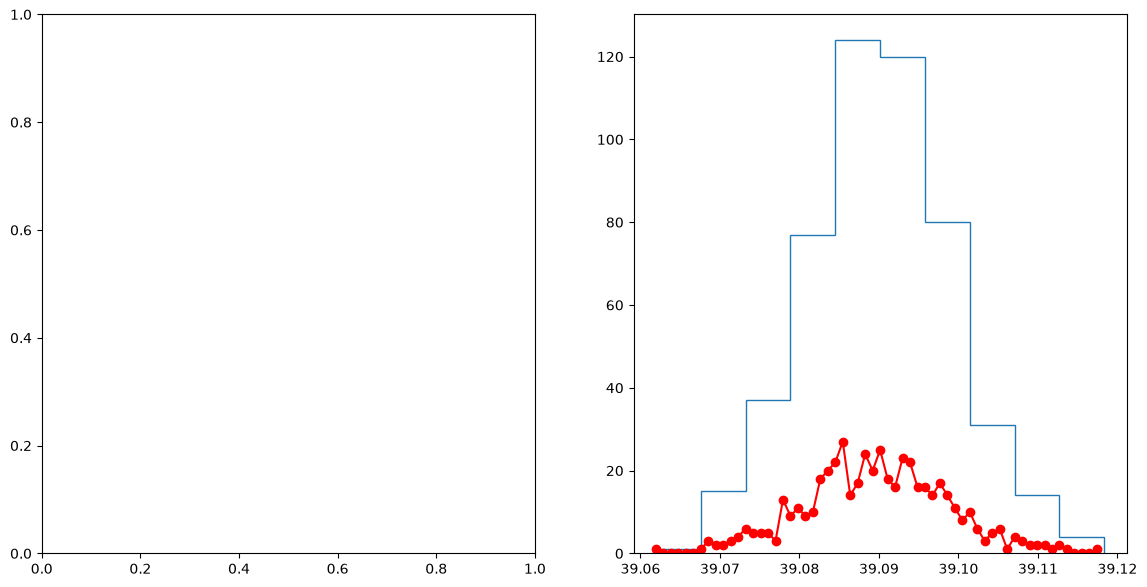

[   21.58784815    39.08953632 13337.83020904]
pos_42.4_42.0_106.0_60.0
[39.07706  39.078365 39.079666 39.08097  39.08227  39.083576 39.08488
 39.08618  39.087486 39.088787 39.09009  39.091396 39.092697 39.094
 39.095303 39.096607 39.09791  39.099213 39.100517 39.101818 39.103123
 39.104427 39.10573  39.107033 39.108334 39.10964  39.110943 39.112244
 39.11355  39.11485  39.116154 39.11746  39.11876  39.120064 39.121365
 39.12267  39.123974 39.125275 39.12658  39.12788  39.129185 39.13049
 39.13179  39.133095 39.134396 39.1357   39.137005 39.138306 39.13961
 39.14091  39.142216 39.14352  39.14482  39.146126 39.147427 39.14873
 39.150036 39.151337 39.15264  39.153942 39.155247] [ 1  0  0  1  0  1  1  1  1  1  0  2  3  0  5  7  2 10  4  7  4  8  9  8
 11 20 14 13 19 26 19 27 21 19 15 17 26 11 20 16 18 20  9 14 12  6  9  7
  7  6  3  4  3  1  1  2  1  1  0  1]


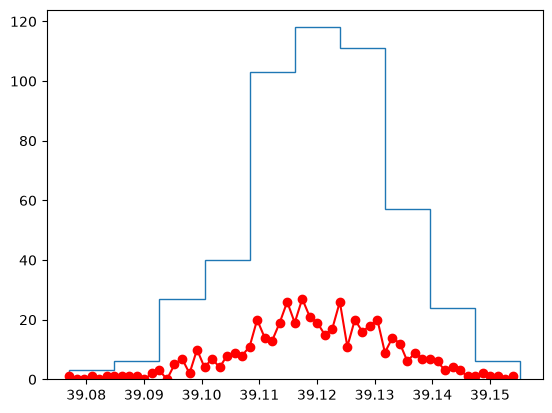

[  20.82200876   39.12020772 6652.08826701]
pos_42.4_42.0_106.0_40.0
[39.071938 39.073135 39.074333 39.07553  39.076725 39.077923 39.07912
 39.08032  39.081516 39.082714 39.083908 39.085106 39.086304 39.0875
 39.0887   39.089897 39.091095 39.09229  39.093487 39.094685 39.095882
 39.09708  39.098278 39.099476 39.10067  39.101868 39.103065 39.104263
 39.10546  39.10666  39.107857 39.10905  39.11025  39.111446 39.112644
 39.113842 39.11504  39.116234 39.11743  39.11863  39.119827 39.121025
 39.122223 39.12342  39.124615 39.125813 39.12701  39.12821  39.129406
 39.130604 39.131798 39.132996 39.134193 39.13539  39.13659  39.137787
 39.138985 39.14018  39.141376 39.142574 39.143772] [ 2  0  0  0  0  1  1  2  2  3  3  5  4  9  9  5 12  9 23 14 21 17 16 26
 21 17 20 19 28 24 26 21 18 18 19  6 11 13 13  7  6  8  4  2  3  2  1  0
  1  0  0  0  0  0  1  0  0  0  0  1]


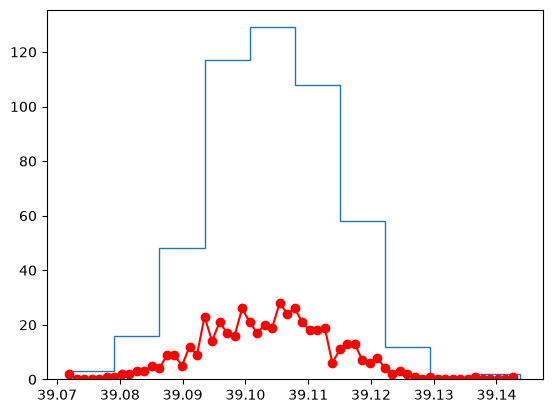

[  23.0913696    39.1037133  9455.64833776]
pos_42.4_42.0_106.0_0.0
[39.053867 39.054657 39.05545  39.05624  39.057034 39.057823 39.058613
 39.059406 39.060196 39.060986 39.06178  39.06257  39.063362 39.06415
 39.06494  39.065735 39.066525 39.067318 39.068108 39.068897 39.06969
 39.07048  39.07127  39.072063 39.072853 39.073647 39.074436 39.075226
 39.07602  39.07681  39.0776   39.078392 39.07918  39.079975 39.080765
 39.081554 39.082348 39.083138 39.08393  39.08472  39.08551  39.086304
 39.087093 39.087883 39.088676 39.089466 39.09026  39.09105  39.09184
 39.092632 39.093422 39.094215 39.095005 39.095795 39.09659  39.097378
 39.098167 39.09896  39.09975  39.100544 39.101334] [ 2  0  2  2  1  1  3  1  1  1  3  7  9  6 10 10 11 16  8 12  5 11 16 12
 17 16 19 18 12 21 26 20 11 21 20 15 14 14 14 11 10 10  6 11 10  4  5  5
  2  5  3  2  1  3  0  2  0  0  0  2]


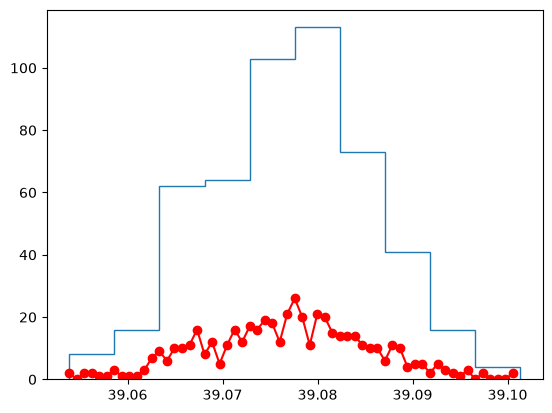

[   18.23728588    39.07690821 13226.41344422]
pos_42.4_42.0_106.0_100.0
[-0.38637915  0.3298283   1.0460358   1.7622432   2.4784505   3.194658
  3.9108653   4.627073    5.3432803   6.059488    6.7756953   7.491903
  8.20811     8.924317    9.640525   10.356732   11.07294    11.789147
 12.505355   13.221562   13.93777    14.653977   15.370185   16.086391
 16.802599   17.518806   18.235014   18.951221   19.667429   20.383636
 21.099844   21.816051   22.532259   23.248466   23.964674   24.680882
 25.397089   26.113297   26.829504   27.545712   28.261919   28.978127
 29.694334   30.410542   31.126749   31.842957   32.559162   33.27537
 33.991577   34.707787   35.423992   36.1402     36.856407   37.572617
 38.288822   39.00503    39.721237   40.437447   41.153652   41.86986
 42.586067  ] [  6   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   5  13  12   8   8   8  20  20   5  1

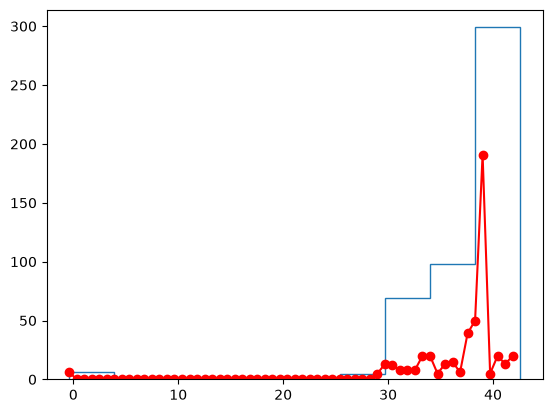

[-1.19100836e-08  2.10998440e+01  5.24629454e+00]
pos_42.4_42.0_106.0_80.0
[39.084152 39.0861   39.088047 39.089996 39.091946 39.093895 39.09584
 39.09779  39.09974  39.101685 39.103634 39.105583 39.10753  39.109478
 39.111427 39.113373 39.115322 39.11727  39.11922  39.121166 39.123116
 39.125065 39.12701  39.12896  39.13091  39.13286  39.134804 39.136753
 39.138702 39.140648 39.142597 39.144547 39.146492 39.14844  39.15039
 39.152336 39.154285 39.156235 39.158184 39.16013  39.16208  39.16403
 39.165974 39.167923 39.169872 39.17182  39.173767 39.175716 39.177666
 39.17961  39.18156  39.18351  39.185455 39.187405 39.189354 39.1913
 39.19325  39.195198 39.197147 39.199093 39.201042] [ 1  1  2  0  0  1  1  0  0  3  1  1  2  2  9  2  3  4  3  9  8  9 13 14
  7 13 12 15 13 14 17 17 21 24 16 20 19 16 16 17 19 16 22 17 17  4  6  4
 10  3  7  8  1  2  0  1  0  1  1  1]


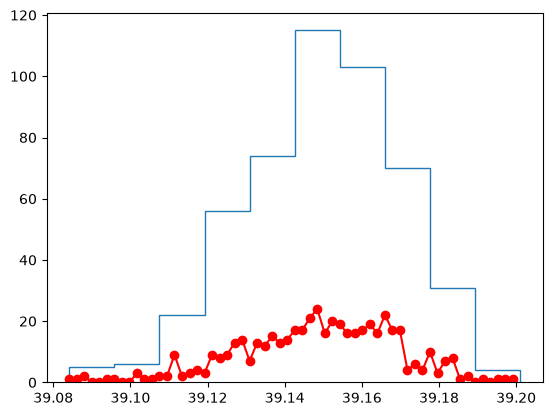

[  19.3548541    39.15065207 2628.6012776 ]
[np.float64(71.83682160728257), np.float64(42.64644944932726), np.float64(59.10487821324151), np.float64(76.64786338806152), np.float64(4.738299438788456), np.float64(24.58677973570647)]
6 6


/tmp/ipykernel_1056450/1148400472.py:64: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


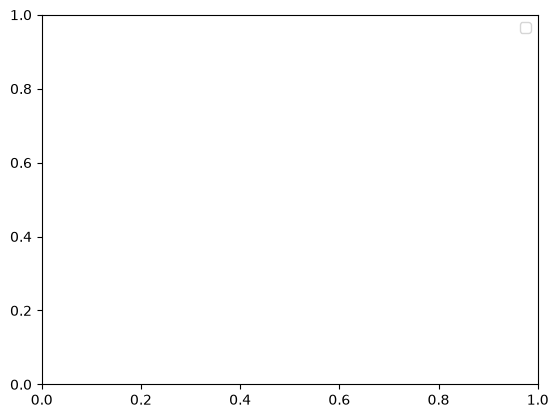

In [54]:
cols = 2
rows = 1
size = 7
channel = 5

fig, ax = plt.subplots(rows, cols, figsize = (size*cols, size*rows))
mean_amps = []
n_events = []
dt_res = []
for lt_i, lt in enumerate(laser_tune):
    for z_i, z in enumerate(Z_range):
        for x_i, x in enumerate(X_range):
            for y_i, y in enumerate(Y_range):
                l = f"pos_{z}_{x}_{y}_{lt}"
                print(l)
                # try:
                mask = (t_peak[l][:,7]>0.96)
                dt = timestamps[l][:,channel] - timestamps[l][:,7]
                mean_amps.append(np.mean(amp[l][mask][:,channel]))
                n_events.append(np.mean(dt[mask]))
                
                nbins = 60
                std = np.std(dt[mask])
                mean = np.mean(dt[mask])
                y, x = np.histogram(dt[mask], bins = nbins)
                x = np.array(x)
                y = np.array(y)
                print(x, y)
                params = curve_fit(gaus, x[0:nbins], y[0:nbins], p0=( np.mean(y), np.mean(x), std)) # , bounds = bounds) # , p0=( np.mean(y), mean, np.std(hist[mask]) ) )
                y_fit = [gaus(i, params[0][0], params[0][1], params[0][2]) for i in x[0:nbins]]
                # plt.show()
                plt.hist(dt[mask], histtype = "step")
                plt.plot(x[0:nbins], y, color = "red", marker = "o")
                plt.show()
                print(params[0])
                dt_res.append(params[0][1])
                # except:
                #     mean_amps.append(0)
                #     n_events.append(0)
print(mean_amps)

sorting = np.argsort(laser_tune)
mean_amps = np.array(mean_amps)
n_events = np.array(n_events)
laser_tune = np.array(laser_tune)
dt_res = np.array(dt_res)

# params = curve_fit(gaus, X_range[mask], mean_amps[mask], p0 = (np.max(mean_amps[mask]), np.mean(X_range[mask]), 10))

print(len(laser_tune), len(mean_amps))

sort = np.argsort(laser_tune)

ax[0].plot(laser_tune[sort], mean_amps[sort], label = f"Z position: {z}", marker = "o")
ax[0].set_xlabel("Laser tune [%]")
ax[0].set_ylabel("Mean amplitude")

ax[1].plot(laser_tune[sort], dt_res[sort], label = f"Z position: {z}", marker = "o")
ax[1].set_xlabel("Laser tune [%]")
ax[1].set_ylabel("Number of events")

ax[0].grid()
ax[1].grid()
plt.legend()
plt.show()